# Scaling with the number of SLM cells

Digital twin of the bench (Supplementary Note 6, Fig. S9). A transmission matrix (TM) has one column per SLM cell, so
it needs at least $N$ patterns for $N$ cells. The physical model fits only the screen $D$, which is band-limited by the
relay and the iris, and each probe supplies as many complex values as the demodulation band holds, independently of
$N$; the number of probes should therefore stay nearly constant as the system grows.

We repeat the focusing and grating experiments of `Focusing.ipynb` and `Imaging.ipynb` for $N = 16^2, 32^2, 64^2,
128^2$ cells and compare three adjoints: the physical model fitted from $K = 10$ probes, and TMs from $N$ and $3N$
patterns. Everything else is as in those notebooks: 150 iterations, five exposures per pattern, ten final reads.
The cell size (40 µm), iris, distances, light level per cell and noise are the same at every $N$; only the aperture and
the camera chip grow (`tw.configure(nc)`), since the object band is set by the iris, not by $N$.

| Metric | Definition |
|---|---|
| model accuracy | correlation of predicted and measured fields of 40 held-out patterns on the $43\times43$ window |
| gradient cosine | cosine between the gradient through the adjoint and the true gradient (only the twin knows it) |
| enhancement η | focus disk intensity / mean over random patterns, mean of the ten final reads |
| grating PSNR | per frame, mean of the ten final reads |

One run (`tw.scaling_run`) is one size, one seed and one task; runs execute in parallel processes, are stored in
`scaling_runs/` and reloaded if the notebook is run again (delete the folder to recompute). The GIF of every model run is
saved in `gifs/`.

**Plan.** `FULL = False` (default, about 20 min on a 10-core laptop): one seed per size, TMs up to $64^2$. `FULL = True`
repeats the plan of Supplementary Note 6: three seeds at $16^2$, $32^2$ and $128^2$, one at $64^2$ (its TM from 12,288
patterns takes most of the time), no TM at $128^2$ (a $16{,}384^2$ Gram matrix does not fit in 16 GB).

In [1]:
import os
import json
import time
import multiprocessing
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
import twin as tw

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9})
os.makedirs("gifs", exist_ok=True)
os.makedirs("scaling_runs", exist_ok=True)
T_START = time.time()

FULL = False
SIZES = [16, 32, 64, 128]
if FULL:
    PLAN = [(nc, s, nc < 128) for nc in (16, 32, 128) for s in (0, 1, 2)] + [(64, 0, True)]
else:
    PLAN = [(nc, 0, nc < 128) for nc in SIZES]
JOBS = [(nc, seed, task, tm) for nc, seed, tm in PLAN for task in ("focus", "grating")]
print(f"{len(JOBS)} runs:", ", ".join(f"{nc}²/s{seed}/{task}{'' if tm else ' (no TM)'}" for nc, seed, task, tm in JOBS))

8 runs: 16²/s0/focus, 16²/s0/grating, 32²/s0/focus, 32²/s0/grating, 64²/s0/focus, 64²/s0/grating, 128²/s0/focus (no TM), 128²/s0/grating (no TM)


**Camera sampling.** At every size the sideband (radius $B$ = 12 lp/mm around the carrier) stays clear of the
$|O|^2$ term (radius $2B$) and below the camera Nyquist frequency, and a noise-free hologram demodulates back to the
field.

In [2]:
for nc in SIZES:
    tw.configure(nc)
    df = 1 / (tw.NU * tw.DX / tw.UP)                       # camera frequency bin (cycles/m)
    fc = tw.FCB * df                                       # carrier per axis
    gap_dc = (np.hypot(fc, fc) - 3 * tw.B) / 1e3           # sideband edge to the |O|^2 disk
    gap_nyq = (tw.UP / (2 * tw.DX) - (fc + tw.B)) / 1e3    # sideband edge to Nyquist (per axis)
    rng = np.random.default_rng(0)
    O = tw.ObjectArm(tw.random_screen(rng)).forward(tw.random_patterns(rng, 1)[0])
    err = np.linalg.norm(tw.demodulate(tw.hologram(O, 14.0), 14.0) - O) / np.linalg.norm(O)
    print(f"{nc:3d}² cells: grid {tw.N}, camera {tw.NU} × {tw.NU} px of 10 µm; sideband clear of |O|² by "
          f"{gap_dc:.1f} lp/mm and of Nyquist by {gap_nyq:.1f} lp/mm; round trip error {err:.0e}")
tw.configure(32)

 16² cells: grid 160, camera 320 × 320 px of 10 µm; sideband clear of |O|² by 3.8 lp/mm and of Nyquist by 9.9 lp/mm; round trip error 4e-06
 32² cells: grid 192, camera 384 × 384 px of 10 µm; sideband clear of |O|² by 3.8 lp/mm and of Nyquist by 9.9 lp/mm; round trip error 2e-06
 64² cells: grid 256, camera 512 × 512 px of 10 µm; sideband clear of |O|² by 3.8 lp/mm and of Nyquist by 9.9 lp/mm; round trip error 2e-06
128² cells: grid 384, camera 768 × 768 px of 10 µm; sideband clear of |O|² by 3.8 lp/mm and of Nyquist by 9.9 lp/mm; round trip error 1e-06


## The runs

In [3]:
def cache(nc, seed, task, tm):
    return f"scaling_runs/{nc}x{nc}_seed{seed}_{task}.json"


todo = sorted([job for job in JOBS if not os.path.exists(cache(*job))], key=lambda job: -job[0] * (3 if job[3] else 1))
t0 = time.time()
with ProcessPoolExecutor(max_workers=4, mp_context=multiprocessing.get_context("spawn")) as pool:
    futures = {job: pool.submit(tw.scaling_run, *job, gif_dir="gifs") for job in todo}     # longest runs first
    for job, future in futures.items():
        json.dump(future.result(), open(cache(*job), "w"))
print(f"{len(todo)} new runs in {time.time() - t0:.0f} s")

RESULTS = [json.load(open(cache(*job))) for job in JOBS]
for o in RESULTS:
    unit = "η" if o["task"] == "focus" else "PSNR"
    print(f"{o['nc']:3d}² seed {o['seed']} {o['task']:7s} | " + "; ".join(
        f"{k}: accuracy {o[k]['accuracy']:.3f}, cosine {o[k]['cos']:.3f}, {unit} {o[k]['final']:.1f}"
        for k in ("model", "tm_N", "tm_3N") if k in o))

0 new runs in 0 s
 16² seed 0 focus   | model: accuracy 0.860, cosine 0.881, η 89.6; tm_N: accuracy 0.788, cosine 0.822, η 71.1; tm_3N: accuracy 0.984, cosine 0.992, η 108.4
 16² seed 0 grating | model: accuracy 0.868, cosine 0.874, PSNR 9.4; tm_N: accuracy 0.886, cosine 0.891, PSNR 9.6; tm_3N: accuracy 0.993, cosine 0.997, PSNR 10.4
 32² seed 0 focus   | model: accuracy 0.851, cosine 0.870, η 136.9; tm_N: accuracy 0.800, cosine 0.816, η 110.2; tm_3N: accuracy 0.985, cosine 0.993, η 186.9
 32² seed 0 grating | model: accuracy 0.858, cosine 0.866, PSNR 16.0; tm_N: accuracy 0.893, cosine 0.900, PSNR 16.2; tm_3N: accuracy 0.994, cosine 0.997, PSNR 16.7
 64² seed 0 focus   | model: accuracy 0.848, cosine 0.867, η 179.2; tm_N: accuracy 0.821, cosine 0.828, η 179.1; tm_3N: accuracy 0.987, cosine 0.993, η 230.4
 64² seed 0 grating | model: accuracy 0.855, cosine 0.858, PSNR 18.1; tm_N: accuracy 0.907, cosine 0.906, PSNR 18.4; tm_3N: accuracy 0.995, cosine 0.997, PSNR 19.1
128² seed 0 focus   

## Results (cf. Supplementary Fig. S9)

Mean ± s.d. over seeds (no error bar with one seed). Model accuracy and gradient cosine are averaged over the focusing
and grating benches.

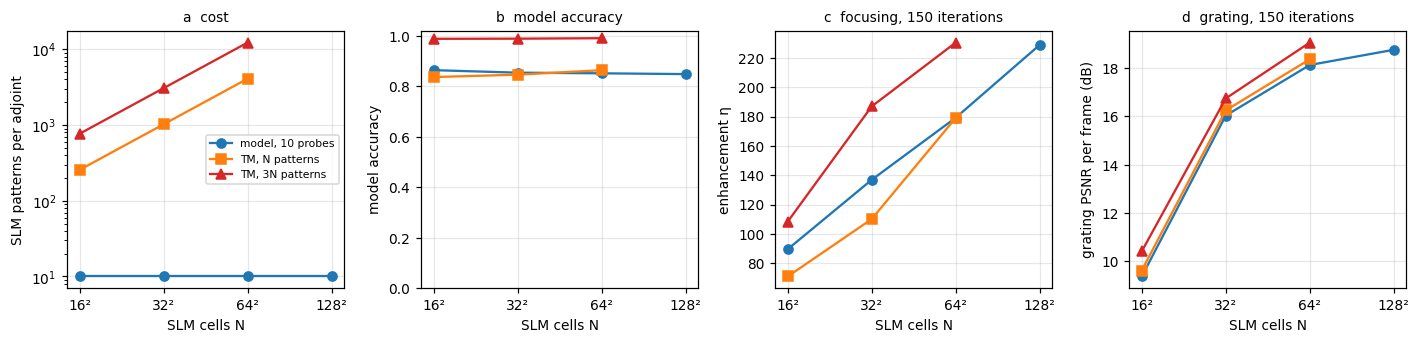

     N adjoint          patterns  accuracy  grad cos        η  PSNR (dB)
   256 model, 10 probes       10     0.864     0.878     89.6       9.37
   256 TM, N patterns        256     0.837     0.857     71.1       9.62
   256 TM, 3N patterns       768     0.988     0.995    108.4      10.41
  1024 model, 10 probes       10     0.854     0.868    136.9      16.04
  1024 TM, N patterns       1024     0.846     0.858    110.2      16.25
  1024 TM, 3N patterns      3072     0.989     0.995    186.9      16.75
  4096 model, 10 probes       10     0.852     0.862    179.2      18.13
  4096 TM, N patterns       4096     0.864     0.867    179.1      18.37
  4096 TM, 3N patterns     12288     0.991     0.995    230.4      19.06
 16384 model, 10 probes       10     0.849     0.854    228.9      18.76


In [4]:
ADJ = {"model": ("model, 10 probes", "C0", "o"), "tm_N": ("TM, N patterns", "C1", "s"), "tm_3N": ("TM, 3N patterns", "C3", "^")}


def series(key, adj, task=None):
    # mean and s.d. over seeds; with task=None, each seed is first averaged over the two benches
    xs, mean, sd = [], [], []
    for nc in SIZES:
        runs = [o for o in RESULTS if o["nc"] == nc and adj in o and (task is None or o["task"] == task)]
        per_seed = [np.mean([o[adj][key] for o in runs if o["seed"] == s]) for s in sorted({o["seed"] for o in runs})]
        if per_seed:
            xs.append(nc * nc); mean.append(np.mean(per_seed)); sd.append(np.std(per_seed))
    return np.array(xs), np.array(mean), np.array(sd)


fig, axs = plt.subplots(1, 4, figsize=(13, 3.2))
for adj, (label, color, marker) in ADJ.items():
    xs, _, _ = series("final", adj, "focus")
    patterns = [10] * len(xs) if adj == "model" else [n * (3 if adj == "tm_3N" else 1) for n in xs]
    axs[0].plot(xs, patterns, marker=marker, color=color, label=label)
    for ax, key, task in [(axs[1], "accuracy", None), (axs[2], "final", "focus"), (axs[3], "final", "grating")]:
        xs, m, s = series(key, adj, task)
        ax.errorbar(xs, m, yerr=s, marker=marker, color=color, capsize=2, label=label)
axs[0].set_yscale("log"); axs[0].set_ylabel("SLM patterns per adjoint"); axs[0].set_title("a  cost")
axs[1].set_ylabel("model accuracy"); axs[1].set_ylim(0, 1.02); axs[1].set_title("b  model accuracy")
axs[2].set_ylabel("enhancement η"); axs[2].set_title("c  focusing, 150 iterations")
axs[3].set_ylabel("grating PSNR per frame (dB)"); axs[3].set_title("d  grating, 150 iterations")
for ax in axs:
    ax.set_xscale("log", base=2); ax.set_xticks([n * n for n in SIZES]); ax.set_xticklabels([f"{n}²" for n in SIZES])
    ax.set_xlabel("SLM cells N"); ax.grid(alpha=0.3)
axs[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

print(f"{'N':>6s} {'adjoint':16s} {'patterns':>8s} {'accuracy':>9s} {'grad cos':>9s} {'η':>8s} {'PSNR (dB)':>10s}")
for nc in SIZES:
    for adj, (label, _, _) in ADJ.items():
        runs = [o for o in RESULTS if o["nc"] == nc and adj in o]
        if not runs:
            continue
        f = [o[adj]["final"] for o in runs if o["task"] == "focus"]
        p = [o[adj]["final"] for o in runs if o["task"] == "grating"]
        print(f"{nc * nc:6d} {label:16s} {runs[0]['patterns'][adj]:8d} {np.mean([o[adj]['accuracy'] for o in runs]):9.3f} "
              f"{np.mean([o[adj]['cos'] for o in runs]):9.3f} {np.mean(f):8.1f} {np.mean(p):10.2f}")

**GIFs of the model runs** at the largest size, where a TM would need 16,384 to 49,152 patterns (all sizes are in
`gifs/scaling_*.gif`).

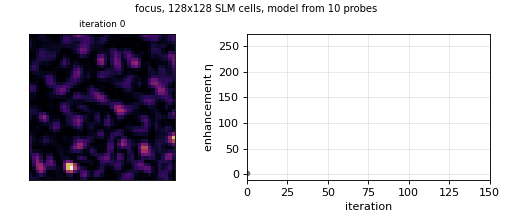

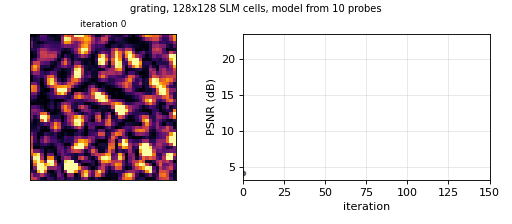

runtime 0 s


In [5]:
for task in ("focus", "grating"):
    display(Image(filename=f"gifs/scaling_{task}_128x128.gif"))
print(f"runtime {time.time() - T_START:.0f} s")

**Take-aways.** At a fixed cost of ten probe patterns, the physical model keeps a model accuracy of
about 0.85 from $16^2$ to $128^2$ cells, and the enhancement and grating PSNR it trains grow with $N$, including at
$128^2$, where a TM would need 16,384 to 49,152 patterns. A TM from $3N$ patterns is nearly exact in the twin, which does
not drift during the acquisition, and trains 1.2–1.4 times the enhancement of the model. A TM from only $N$ patterns
depends on how the unknown phase of each pattern is initialised: started from the physical model, as here and on the
bench (Supplementary Note 3C), it comes close to the model; started from free space, it reached a model accuracy of
only 0.37–0.71.